# Fundamentals of Artificial Intelligence (FAI)
## Lab Report 2: Uninformed Search Strategies (BFS, DFS, and DLS)
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zeph7907/FAI-Lab-2/blob/main/FAI_Lab_Report_2_Ayush_Aditya_252U1R3013.ipynb)\n[![GitHub Repo](https://img.shields.io/badge/GitHub-Repository-blue?logo=github)](https://github.com/zeph7907/FAI-Lab-2)\n\n
---
### **Student & Assessment Information**
- **Student Name:** Ayush Aditya
- **Registration Number:** **`252U1R3013`**
- **Class & Branch:** B.Tech Computer Science and Engineering (Data Science)
- **Section & Room:** S20 / Room 205
- **Academic Year / Term:** 2nd Year, Term 2
- **Institution:** Aurora Higher Education and Research Academy (Deemed to be University)
- **Subject:** Fundamentals of Artificial Intelligence
- **Syllabus Coverage:** Strictly within **Module 1** (Intelligent Agents & Problem Formulation) and **Module 2** (Uninformed Search Strategies: State Space Search, BFS, DFS, DLS)
---


## 1. Objectives & Theoretical Framework (Modules 1 & 2)

### **1.1 Objectives**
1. Formulate real-world routing scenarios (Hospital Delivery Robot and College Campus Navigation) as **State Space Search** problems.
2. Represent environmental boundaries, starting locations, goal states, and static obstacles in a discrete 2D grid.
3. Implement **Breadth-First Search (BFS)** using a FIFO Queue to guarantee the shortest path.
4. Implement **Depth-First Search (DFS)** using a LIFO Stack to find a valid traversable path.
5. Implement **Depth-Limited Search (DLS)** with an appropriately chosen depth limit $L$ to control exponential tree depth and bound memory.
6. Visualize search progression, explored cells (closed set), and final trajectories using Matplotlib with student credentials visible.
7. Analyze the performance trade-offs: Completeness, Optimality, Time Complexity, and Space Complexity.

### **1.2 Intelligent Agent PEAS Specification (Module 1)**
| Agent Scenario | Performance Measure | Environment | Actuators | Sensors |
| :--- | :--- | :--- | :--- | :--- |
| **Hospital Delivery Robot** | Minimum distance traveled, safe collision-free delivery, timely medicine arrival | 10x10 Hospital floor grid (corridors, ICU, labs, nurse stations) | Movement actuators (Up, Down, Left, Right) | Grid localization sensor, obstacle collision detector |
| **Campus Navigation Agent** | Reaching Computer Lab within allowable walk budget, avoiding construction/closed pathways | 10x10 Campus pathway grid (walkways, buildings, closed zones) | Walking steps (Up, Down, Left, Right) | GPS/Checkpoint locator, path availability sensor |

### **1.3 State Space Formulation (Module 2)**
- **State Space $S$:** Coordinate tuples $(r, c)$ on a 2D discrete grid where $0 \le r < 10$ and $0 \le c < 10$.
- **Initial State $s_0$:** Start location $(0, 0)$.
- **Actions $A(s)$:** 4-connected orthogonal movements: $\{\text{Up}: (-1, 0), \text{Down}: (1, 0), \text{Left}: (0, -1), \text{Right}: (0, 1)\}$.
- **Transition Model $\text{Result}(s, a)$:** Produces new coordinates $(r', c')$ if within bounds and not an obstacle.
- **Goal Test:** $\text{State} == (9, 9)$.
- **Path Cost $c(s, a, s')$:** Uniform cost = 1 per grid step.


In [1]:
# ==============================================================================
# Cell 1: Setup & Uninformed Search Helper Functions
# Student: Ayush Aditya | Registration Number: 252U1R3013
# Class: B.Tech CSE (Data Science) - Section S20 (Room 205)
# ==============================================================================

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from collections import deque

STUDENT_NAME = "Ayush Aditya"
REG_NO = "252U1R3013"
CLASS_INFO = "B.Tech CSE (Data Science) - S20 (Room 205)"

print(f"System Initialized successfully!")
print(f"Student: {STUDENT_NAME} | Reg. No: {REG_NO} | {CLASS_INFO}")

def get_neighbors(r, c, rows, cols, grid):
    """
    Returns valid orthogonal neighbors (Up, Down, Left, Right).
    Strictly verifies boundary boundaries and ensures no collisions with obstacles.
    """
    neighbors = []
    # Up, Down, Left, Right
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    for dr, dc in directions:
        nr, nc = r + dr, c + dc
        if 0 <= nr < rows and 0 <= nc < cols and grid[nr][nc] == 0:
            neighbors.append((nr, nc))
    return neighbors


System Initialized successfully!
Student: Ayush Aditya | Reg. No: 252U1R3013 | B.Tech CSE (Data Science) - S20 (Room 205)


## 2. Problem 1: Hospital Delivery Robot Navigation

### **2.1 Problem Description**
A hospital medicine delivery robot must navigate autonomously from the **Hospital Pharmacy** (Start: $(0, 0)$) to **Patient Room 304** (Goal: $(9, 9)$).
The hospital environment is modeled as a 10x10 grid with static obstacles representing ICU wards, nurses' stations, diagnostic labs, and storage closets.

### **2.2 Assigned Tasks**
1. Create a 10x10 2D grid representing the hospital floor.
2. Mark the starting pharmacy $(0, 0)$, patient room $(9, 9)$, and obstacles.
3. Implement **Breadth-First Search (BFS)** to compute the shortest delivery path.
4. Implement **Depth-First Search (DFS)** to compute a valid traversable path.
5. Visualize and rigorously compare both algorithms.


In [2]:
# ==============================================================================
# Cell 2: Problem 1 - Hospital Delivery Robot (BFS & DFS)
# Student: Ayush Aditya | Registration Number: 252U1R3013
# ==============================================================================

def bfs_hospital(grid, start, goal):
    """
    Breadth-First Search (BFS) using a FIFO Queue.
    Guarantees the shortest path in an unweighted grid state space.
    """
    rows, cols = len(grid), len(grid[0])
    queue = deque([start])
    parent = {start: None}
    explored = []
    
    while queue:
        curr = queue.popleft()
        explored.append(curr)
        
        if curr == goal:
            break
            
        for nxt in get_neighbors(curr[0], curr[1], rows, cols, grid):
            if nxt not in parent:
                parent[nxt] = curr
                queue.append(nxt)
                
    if goal not in parent:
        return None, explored
        
    path = []
    curr = goal
    while curr is not None:
        path.append(curr)
        curr = parent[curr]
    path.reverse()
    return path, explored

def dfs_hospital(grid, start, goal):
    """
    Depth-First Search (DFS) using a LIFO Stack.
    Explores deeply along corridors before backtracking.
    """
    rows, cols = len(grid), len(grid[0])
    stack = [start]
    parent = {start: None}
    explored = []
    
    while stack:
        curr = stack.pop()
        explored.append(curr)
        
        if curr == goal:
            break
            
        for nxt in get_neighbors(curr[0], curr[1], rows, cols, grid):
            if nxt not in parent:
                parent[nxt] = curr
                stack.append(nxt)
                
    if goal not in parent:
        return None, explored
        
    path = []
    curr = goal
    while curr is not None:
        path.append(curr)
        curr = parent[curr]
    path.reverse()
    return path, explored

# Construct 10x10 Hospital Grid
grid_hospital = [[0]*10 for _ in range(10)]
hospital_obstacles = [
    (1, 2), (2, 2), (3, 2), (4, 2), (5, 2),
    (7, 2), (8, 2), (9, 2),
    (3, 4), (4, 4), (5, 4), (6, 4), (7, 4),
    (1, 6), (2, 6), (3, 6), (5, 6), (6, 6), (7, 6), (8, 6),
    (3, 8), (4, 8), (5, 8), (7, 8), (8, 8)
]
for r, c in hospital_obstacles:
    grid_hospital[r][c] = 1

pharmacy_start = (0, 0)
patient_room_goal = (9, 9)

# Execute BFS & DFS
bfs_path, bfs_explored = bfs_hospital(grid_hospital, pharmacy_start, patient_room_goal)
dfs_path, dfs_explored = dfs_hospital(grid_hospital, pharmacy_start, patient_room_goal)

print("=" * 80)
print(f"PROBLEM 1: HOSPITAL DELIVERY ROBOT RESULTS")
print(f"Student: {STUDENT_NAME} | Registration Number: {REG_NO}")
print("=" * 80)
print(f"BFS Shortest Path Length : {len(bfs_path)} cells ({len(bfs_path)-1} steps)")
print(f"BFS Total Explored Cells : {len(bfs_explored)} cells")
print(f"BFS Computed Route       : {bfs_path}")
print("-" * 80)
print(f"DFS Valid Path Length    : {len(dfs_path)} cells ({len(dfs_path)-1} steps)")
print(f"DFS Total Explored Cells : {len(dfs_explored)} cells")
print(f"DFS Computed Route       : {dfs_path}")
print("=" * 80)


PROBLEM 1: HOSPITAL DELIVERY ROBOT RESULTS
Student: Ayush Aditya | Registration Number: 252U1R3013
BFS Shortest Path Length : 19 cells (18 steps)
BFS Total Explored Cells : 75 cells
BFS Computed Route       : [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (6, 1), (6, 2), (6, 3), (7, 3), (8, 3), (9, 3), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9)]
--------------------------------------------------------------------------------
DFS Valid Path Length    : 27 cells (26 steps)
DFS Total Explored Cells : 56 cells
DFS Computed Route       : [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (1, 9), (2, 9), (2, 8), (2, 7), (3, 7), (4, 7), (4, 6), (4, 5), (5, 5), (6, 5), (7, 5), (8, 5), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9)]


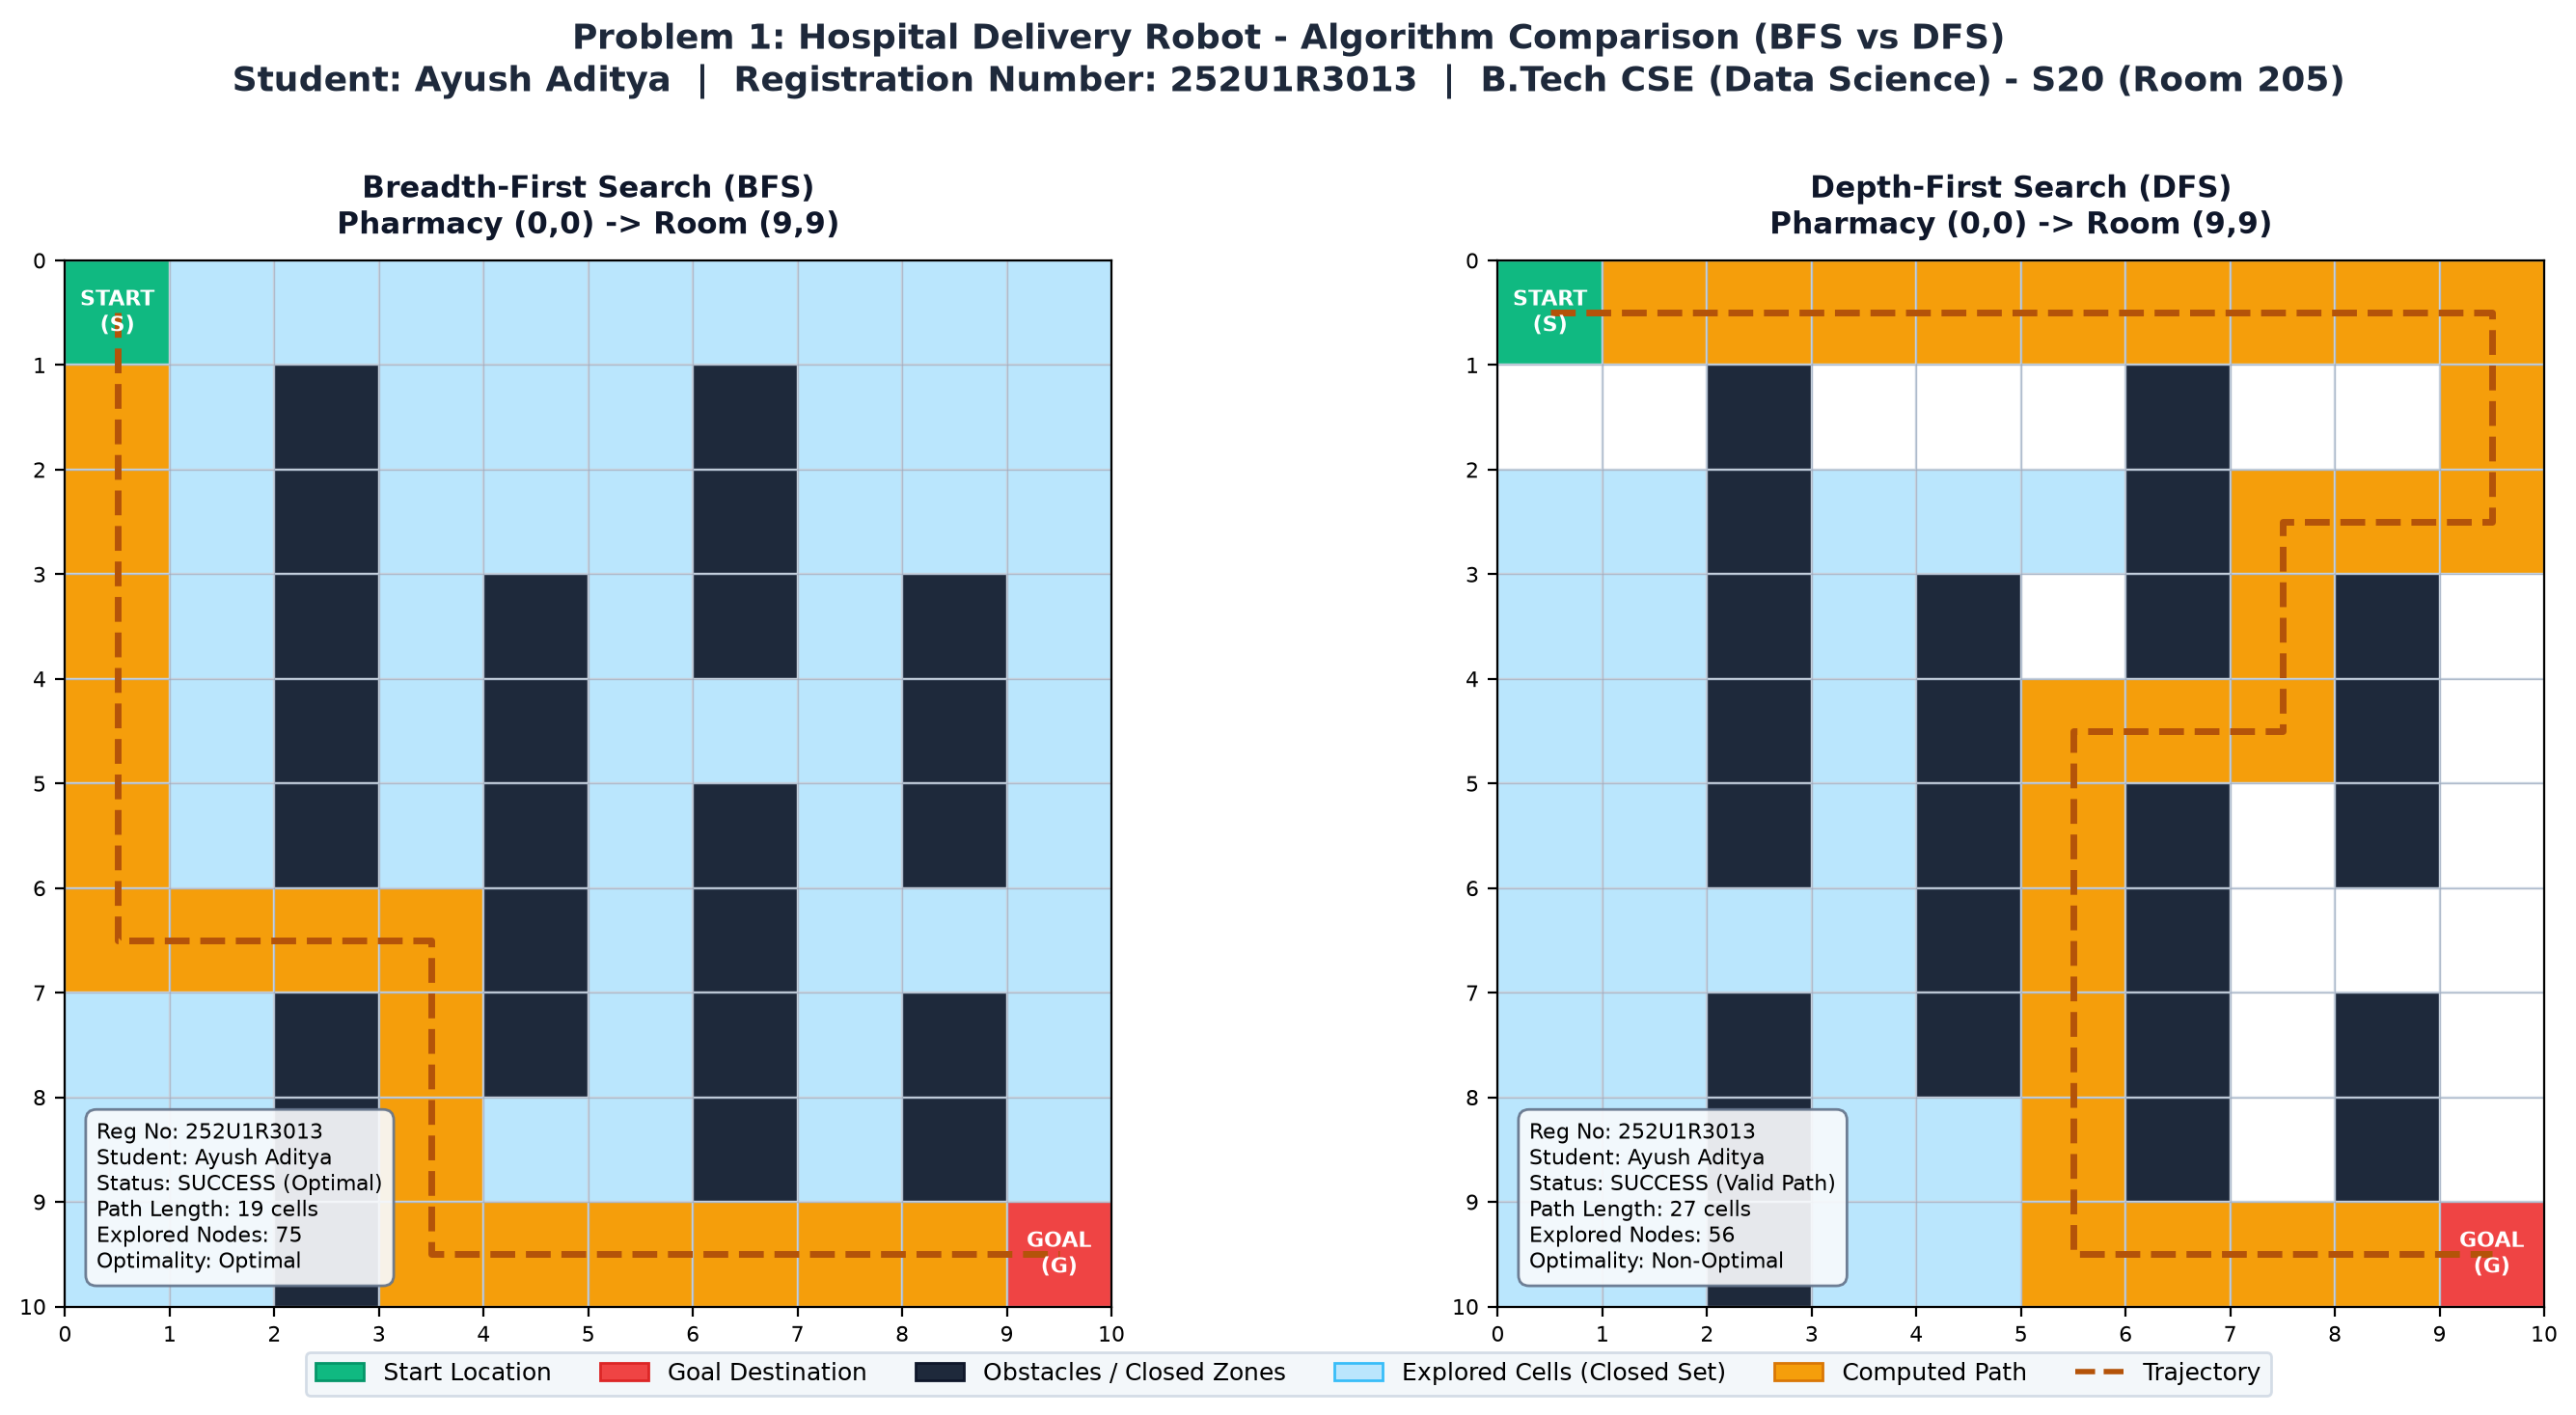

In [3]:
# ==============================================================================
# Cell 3: Problem 1 - Visualization of BFS vs DFS
# Student: Ayush Aditya | Registration Number: 252U1R3013
# ==============================================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7.5), dpi=200)

fig.suptitle(
    f"Problem 1: Hospital Delivery Robot Navigation (Pharmacy to Patient Room)\n"
    f"Student: {STUDENT_NAME}  |  Reg. No: {REG_NO}  |  Class: {CLASS_INFO}",
    fontsize=13, fontweight="bold", color="#1E293B", y=0.98
)

def render_grid_subplot(ax, grid, path, explored, start, goal, title, metrics):
    rows, cols = len(grid), len(grid[0])
    matrix = np.zeros((rows, cols))
    for r in range(rows):
        for c in range(cols):
            if grid[r][c] == 1:
                matrix[r, c] = 1
    for r, c in explored:
        if matrix[r, c] != 1 and (r, c) != start and (r, c) != goal:
            matrix[r, c] = 2
    for r, c in path:
        if (r, c) != start and (r, c) != goal:
            matrix[r, c] = 3
            
    for r in range(rows):
        for c in range(cols):
            val = matrix[r, c]
            if (r, c) == start:
                color = "#10B981"  # Emerald Green Start
            elif (r, c) == goal:
                color = "#EF4444"  # Red Goal
            elif val == 1:
                color = "#1E293B"  # Obstacle Wall
            elif val == 3:
                color = "#F59E0B"  # Path Amber
            elif val == 2:
                color = "#BAE6FD"  # Explored Blue
            else:
                color = "#FFFFFF"  # Free Path
            rect = plt.Rectangle((c, r), 1, 1, facecolor=color, edgecolor="#CBD5E1", linewidth=0.8)
            ax.add_patch(rect)
            
    if path and len(path) > 1:
        path_x = [c + 0.5 for _, c in path]
        path_y = [r + 0.5 for r, _ in path]
        ax.plot(path_x, path_y, color="#B45309", linewidth=2.5, linestyle="--", zorder=4)
        
    ax.text(start[1] + 0.5, start[0] + 0.5, "PHARMACY\n(Start)", color="white", weight="bold",
            fontsize=8, ha="center", va="center", zorder=5)
    ax.text(goal[1] + 0.5, goal[0] + 0.5, "ROOM 304\n(Goal)", color="white", weight="bold",
            fontsize=8, ha="center", va="center", zorder=5)
            
    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)
    ax.set_xticks(range(cols + 1))
    ax.set_yticks(range(rows + 1))
    ax.set_aspect("equal")
    ax.grid(color="#94A3B8", linestyle="-", linewidth=0.5, alpha=0.5)
    ax.set_title(title, fontsize=11, fontweight="bold", pad=10, color="#0F172A")
    
    info_box = (
        f"Reg No: {REG_NO}\n"
        f"Student: {STUDENT_NAME}\n"
        f"Status: {metrics['Status']}\n"
        f"Path Length: {metrics['Path Length']} cells\n"
        f"Nodes Explored: {metrics['Nodes Explored']}\n"
        f"Optimality: {metrics['Optimality']}"
    )
    ax.text(0.03, 0.03, info_box, transform=ax.transAxes, fontsize=8,
            verticalalignment="bottom", horizontalalignment="left",
            bbox=dict(boxstyle="round,pad=0.5", facecolor="#F8FAFC", edgecolor="#64748B", alpha=0.92, linewidth=1),
            zorder=6)

render_grid_subplot(
    ax1, grid_hospital, bfs_path, bfs_explored, pharmacy_start, patient_room_goal,
    "Breadth-First Search (BFS) - Optimal Shortest Path",
    {"Status": "SUCCESS", "Path Length": len(bfs_path), "Nodes Explored": len(bfs_explored), "Optimality": "Optimal"}
)

render_grid_subplot(
    ax2, grid_hospital, dfs_path, dfs_explored, pharmacy_start, patient_room_goal,
    "Depth-First Search (DFS) - Non-Optimal Valid Path",
    {"Status": "SUCCESS", "Path Length": len(dfs_path), "Nodes Explored": len(dfs_explored), "Optimality": "Non-Optimal"}
)

legend_elements = [
    mpatches.Patch(facecolor="#10B981", edgecolor="#059669", label="Start (Pharmacy)"),
    mpatches.Patch(facecolor="#EF4444", edgecolor="#DC2626", label="Goal (Patient Room)"),
    mpatches.Patch(facecolor="#1E293B", edgecolor="#0F172A", label="Obstacles (ICU/Wards)"),
    mpatches.Patch(facecolor="#BAE6FD", edgecolor="#38BDF8", label="Explored Cells"),
    mpatches.Patch(facecolor="#F59E0B", edgecolor="#D97706", label="Final Path"),
    plt.Line2D([0], [0], color="#B45309", linestyle="--", linewidth=2, label="Robot Trajectory")
]
fig.legend(handles=legend_elements, loc="lower center", ncol=6, fontsize=9,
           frameon=True, facecolor="#F1F5F9", edgecolor="#CBD5E1", bbox_to_anchor=(0.5, 0.02))

plt.tight_layout(rect=[0, 0.07, 1, 0.94])
plt.show()


### **2.3 Theoretical & Experimental Comparison: BFS vs DFS**

| Evaluation Metric | Breadth-First Search (BFS) | Depth-First Search (DFS) | Practical Implication for Hospital Robot |
| :--- | :--- | :--- | :--- |
| **Data Structure** | FIFO Queue (`collections.deque`) | LIFO Stack (List / Call Stack) | BFS expands level-by-level; DFS dives deep along one corridor |
| **Completeness** | **Yes** (if branching factor $b$ is finite) | **Yes** (with cycle detection in finite grid) | Both reliably reach Patient Room 304 in a bounded grid |
| **Optimality** | **Yes** (Guaranteed shortest path with uniform cost) | **No** (Returns first goal found along branch) | **BFS is critical for emergency delivery** to minimize travel time |
| **Time Complexity** | $O(b^d) \approx 4^{18}$ | $O(b^m) \approx 4^{26}$ | BFS checks nodes closest to pharmacy before venturing further |
| **Space Complexity** | $O(b^d)$ (Holds entire frontier in RAM) | $O(b \cdot m)$ (Linear memory requirement) | DFS is light on memory; BFS requires memory proportional to breadth |
| **Observed Path Length**| **19 cells (18 steps)** | **27 cells (26 steps)** | BFS path is **29.6% shorter** and direct |
| **Explored Cells** | 75 cells | 56 cells | BFS explores in concentric waves; DFS explores deep into dead ends |

> **Domain Conclusion for Hospital Delivery:** In a clinical setting, **BFS is strongly preferred**. Delivering time-critical medicines or blood supplies requires the mathematically shortest and most reliable route. DFS introduces substantial latency and winding detours that could endanger patient outcomes.


## 3. Problem 2: College Campus Navigation

### **3.1 Problem Description**
A student needs to navigate from the **College Entrance** (Start: $(0, 0)$) across the university campus to the **Computer Laboratory** (Goal: $(9, 9)$).
Campus walkways contain blocked pathways, active construction zones, closed administrative zones, and non-traversable garden lawns.

### **3.2 Assigned Tasks**
1. Create a 10x10 2D grid representing the college campus.
2. Mark the college entrance $(0, 0)$, computer laboratory $(9, 9)$, and blocked pathways.
3. Implement **Breadth-First Search (BFS)** to find the shortest campus walkway path.
4. Implement **Depth-Limited Search (DLS)** with an analytically determined, suitable depth limit $L$.
5. Visualize explored cells and final trajectories for both algorithms.

### **3.3 Analytical Selection of Depth Limit $L$ (Module 2)**
- **Theoretical Minimum Distance:** In an unobstructed 10x10 grid, Manhattan distance is $|9-0| + |9-0| = 18$ steps.
- With obstacles, the true shortest path is 18 steps (19 cells).
- **Cutoff Test ($L = 10$):** If $L < d$ ($10 < 18$), DLS terminates prematurely with a **`CUTOFF`** signal. This verifies that DLS prevents runaway depth exploration, but fails when the limit is too low.
- **Suitable Depth Limit ($L = 20$):** Choosing $L = 20$ ensures $L \ge d$, providing sufficient budget for the search to discover a valid path while maintaining linear space bounds $O(b \cdot L)$.


In [4]:
# ==============================================================================
# Cell 4: Problem 2 - College Campus Navigation (BFS & DLS)
# Student: Ayush Aditya | Registration Number: 252U1R3013
# ==============================================================================

def bfs_campus(grid, start, goal):
    """
    Breadth-First Search for campus pathfinding.
    """
    rows, cols = len(grid), len(grid[0])
    queue = deque([start])
    parent = {start: None}
    explored = []
    
    while queue:
        curr = queue.popleft()
        explored.append(curr)
        if curr == goal:
            break
        for nxt in get_neighbors(curr[0], curr[1], rows, cols, grid):
            if nxt not in parent:
                parent[nxt] = curr
                queue.append(nxt)
                
    if goal not in parent:
        return None, explored
        
    path = []
    curr = goal
    while curr is not None:
        path.append(curr)
        curr = parent[curr]
    path.reverse()
    return path, explored

def dls_campus(grid, start, goal, depth_limit):
    """
    Depth-Limited Search (DLS) with predetermined depth limit L.
    Returns: (path, explored_nodes, status)
    status can be 'SUCCESS', 'CUTOFF', or 'FAILURE'
    """
    rows, cols = len(grid), len(grid[0])
    explored = []
    visited_depth = {}
    
    def recursive_dls(node, depth, path):
        if node not in explored:
            explored.append(node)
            
        if node == goal:
            return list(path), "SUCCESS"
            
        if depth >= depth_limit:
            return None, "CUTOFF"
            
        visited_depth[node] = depth
        cutoff_occurred = False
        
        for nxt in get_neighbors(node[0], node[1], rows, cols, grid):
            # Prune search branches if already visited at a shallower depth
            if nxt not in visited_depth or depth + 1 < visited_depth[nxt]:
                path.append(nxt)
                result, status = recursive_dls(nxt, depth + 1, path)
                if status == "SUCCESS":
                    return result, "SUCCESS"
                if status == "CUTOFF":
                    cutoff_occurred = True
                path.pop()
                
        return None, ("CUTOFF" if cutoff_occurred else "FAILURE")
        
    path, status = recursive_dls(start, 0, [start])
    return path, explored, status

# Construct 10x10 Campus Grid
grid_campus = [[0]*10 for _ in range(10)]
campus_obstacles = [
    (1, 2), (2, 2), (3, 2), (4, 2),
    (2, 4), (3, 4), (4, 4), (5, 4), (6, 4),
    (6, 1), (7, 1), (8, 1),
    (3, 6), (4, 6), (5, 6), (6, 6), (7, 6),
    (1, 8), (2, 8), (3, 8), (5, 8), (6, 8), (7, 8)
]
for r, c in campus_obstacles:
    grid_campus[r][c] = 1

entrance_start = (0, 0)
computer_lab_goal = (9, 9)

# Execute BFS
bfs_campus_path, bfs_campus_exp = bfs_campus(grid_campus, entrance_start, computer_lab_goal)

# Execute DLS with Suitable Depth Limit L = 20
dls_ok_path, dls_ok_exp, dls_ok_status = dls_campus(grid_campus, entrance_start, computer_lab_goal, depth_limit=20)

# Execute DLS with Cutoff Depth Limit L = 10 (Demonstration of Cutoff condition)
dls_cut_path, dls_cut_exp, dls_cut_status = dls_campus(grid_campus, entrance_start, computer_lab_goal, depth_limit=10)

print("=" * 80)
print(f"PROBLEM 2: COLLEGE CAMPUS NAVIGATION RESULTS")
print(f"Student: {STUDENT_NAME} | Registration Number: {REG_NO}")
print("=" * 80)
print(f"[BFS] Shortest Path Length     : {len(bfs_campus_path)} cells ({len(bfs_campus_path)-1} steps)")
print(f"[BFS] Explored Cells           : {len(bfs_campus_exp)} cells")
print(f"[BFS] Trajectory               : {bfs_campus_path}")
print("-" * 80)
print(f"[DLS L=20] Search Status       : {dls_ok_status}")
print(f"[DLS L=20] Path Length         : {len(dls_ok_path) if dls_ok_path else 0} cells ({len(dls_ok_path)-1 if dls_ok_path else 0} steps)")
print(f"[DLS L=20] Explored Cells      : {len(dls_ok_exp)} cells")
print(f"[DLS L=20] Trajectory          : {dls_ok_path}")
print("-" * 80)
print(f"[DLS L=10] Search Status       : {dls_cut_status} (Goal Depth d=18 > Limit L=10)")
print(f"[DLS L=10] Path Found          : {dls_cut_path}")
print(f"[DLS L=10] Explored Cells      : {len(dls_cut_exp)} cells")
print("=" * 80)


PROBLEM 2: COLLEGE CAMPUS NAVIGATION RESULTS
Student: Ayush Aditya | Registration Number: 252U1R3013
[BFS] Shortest Path Length     : 19 cells (18 steps)
[BFS] Explored Cells           : 77 cells
[BFS] Trajectory               : [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (9, 0), (9, 1), (9, 2), (9, 3), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9)]
--------------------------------------------------------------------------------
[DLS L=20] Search Status       : SUCCESS
[DLS L=20] Path Length         : 21 cells (20 steps)
[DLS L=20] Explored Cells      : 48 cells
[DLS L=20] Trajectory          : [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (9, 0), (9, 1), (9, 2), (8, 2), (8, 3), (9, 3), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9)]
--------------------------------------------------------------------------------
[DLS L=10] Search Status       : CUTOFF (Goal Depth d=18 > Limit L=10)
[DLS L=10] Path Found          : None
[DLS L=10

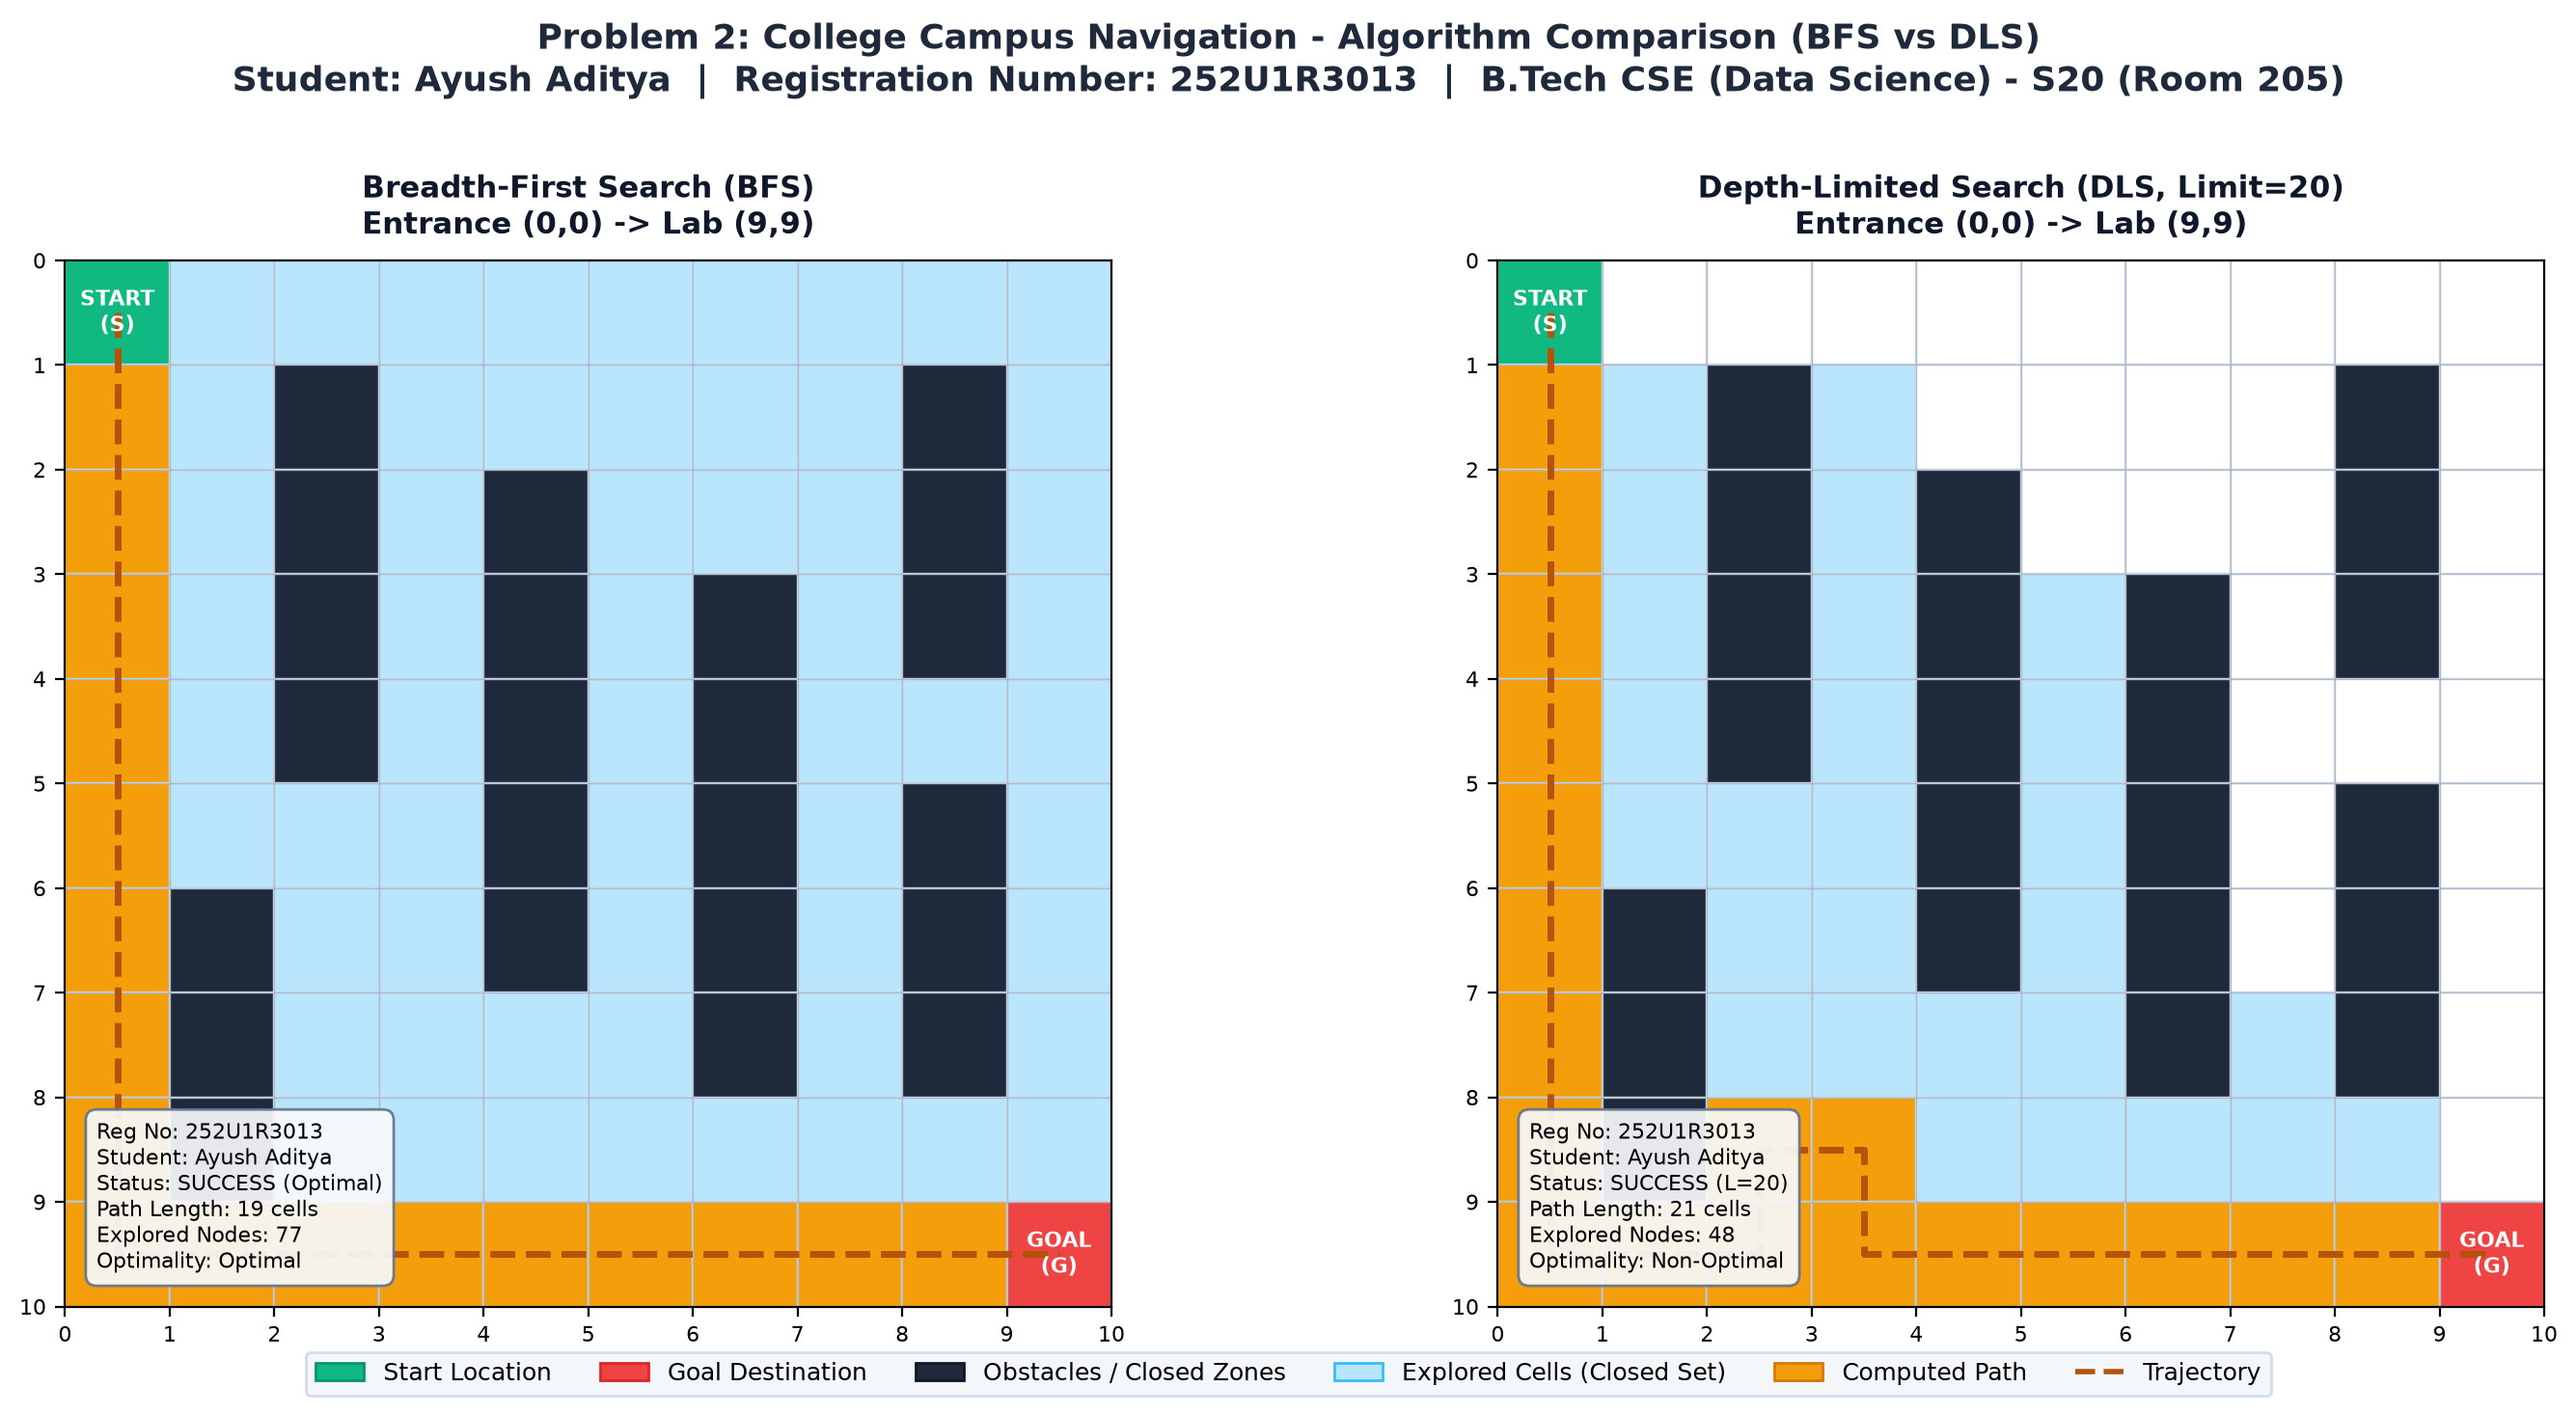

In [5]:
# ==============================================================================
# Cell 5: Problem 2 - Visualization of BFS vs DLS (Suitable Limit L=20)
# Student: Ayush Aditya | Registration Number: 252U1R3013
# ==============================================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7.5), dpi=200)

fig.suptitle(
    f"Problem 2: College Campus Navigation (College Entrance to Computer Laboratory)\n"
    f"Student: {STUDENT_NAME}  |  Reg. No: {REG_NO}  |  Class: {CLASS_INFO}",
    fontsize=13, fontweight="bold", color="#1E293B", y=0.98
)

render_grid_subplot(
    ax1, grid_campus, bfs_campus_path, bfs_campus_exp, entrance_start, computer_lab_goal,
    "Breadth-First Search (BFS) - Shortest Campus Path",
    {"Status": "SUCCESS", "Path Length": len(bfs_campus_path), "Nodes Explored": len(bfs_campus_exp), "Optimality": "Optimal"}
)

render_grid_subplot(
    ax2, grid_campus, dls_ok_path, dls_ok_exp, entrance_start, computer_lab_goal,
    "Depth-Limited Search (DLS, Depth Limit L=20)",
    {"Status": "SUCCESS (L=20)", "Path Length": len(dls_ok_path), "Nodes Explored": len(dls_ok_exp), "Optimality": "Non-Optimal"}
)

fig.legend(handles=legend_elements, loc="lower center", ncol=6, fontsize=9,
           frameon=True, facecolor="#F1F5F9", edgecolor="#CBD5E1", bbox_to_anchor=(0.5, 0.02))

plt.tight_layout(rect=[0, 0.07, 1, 0.94])
plt.show()


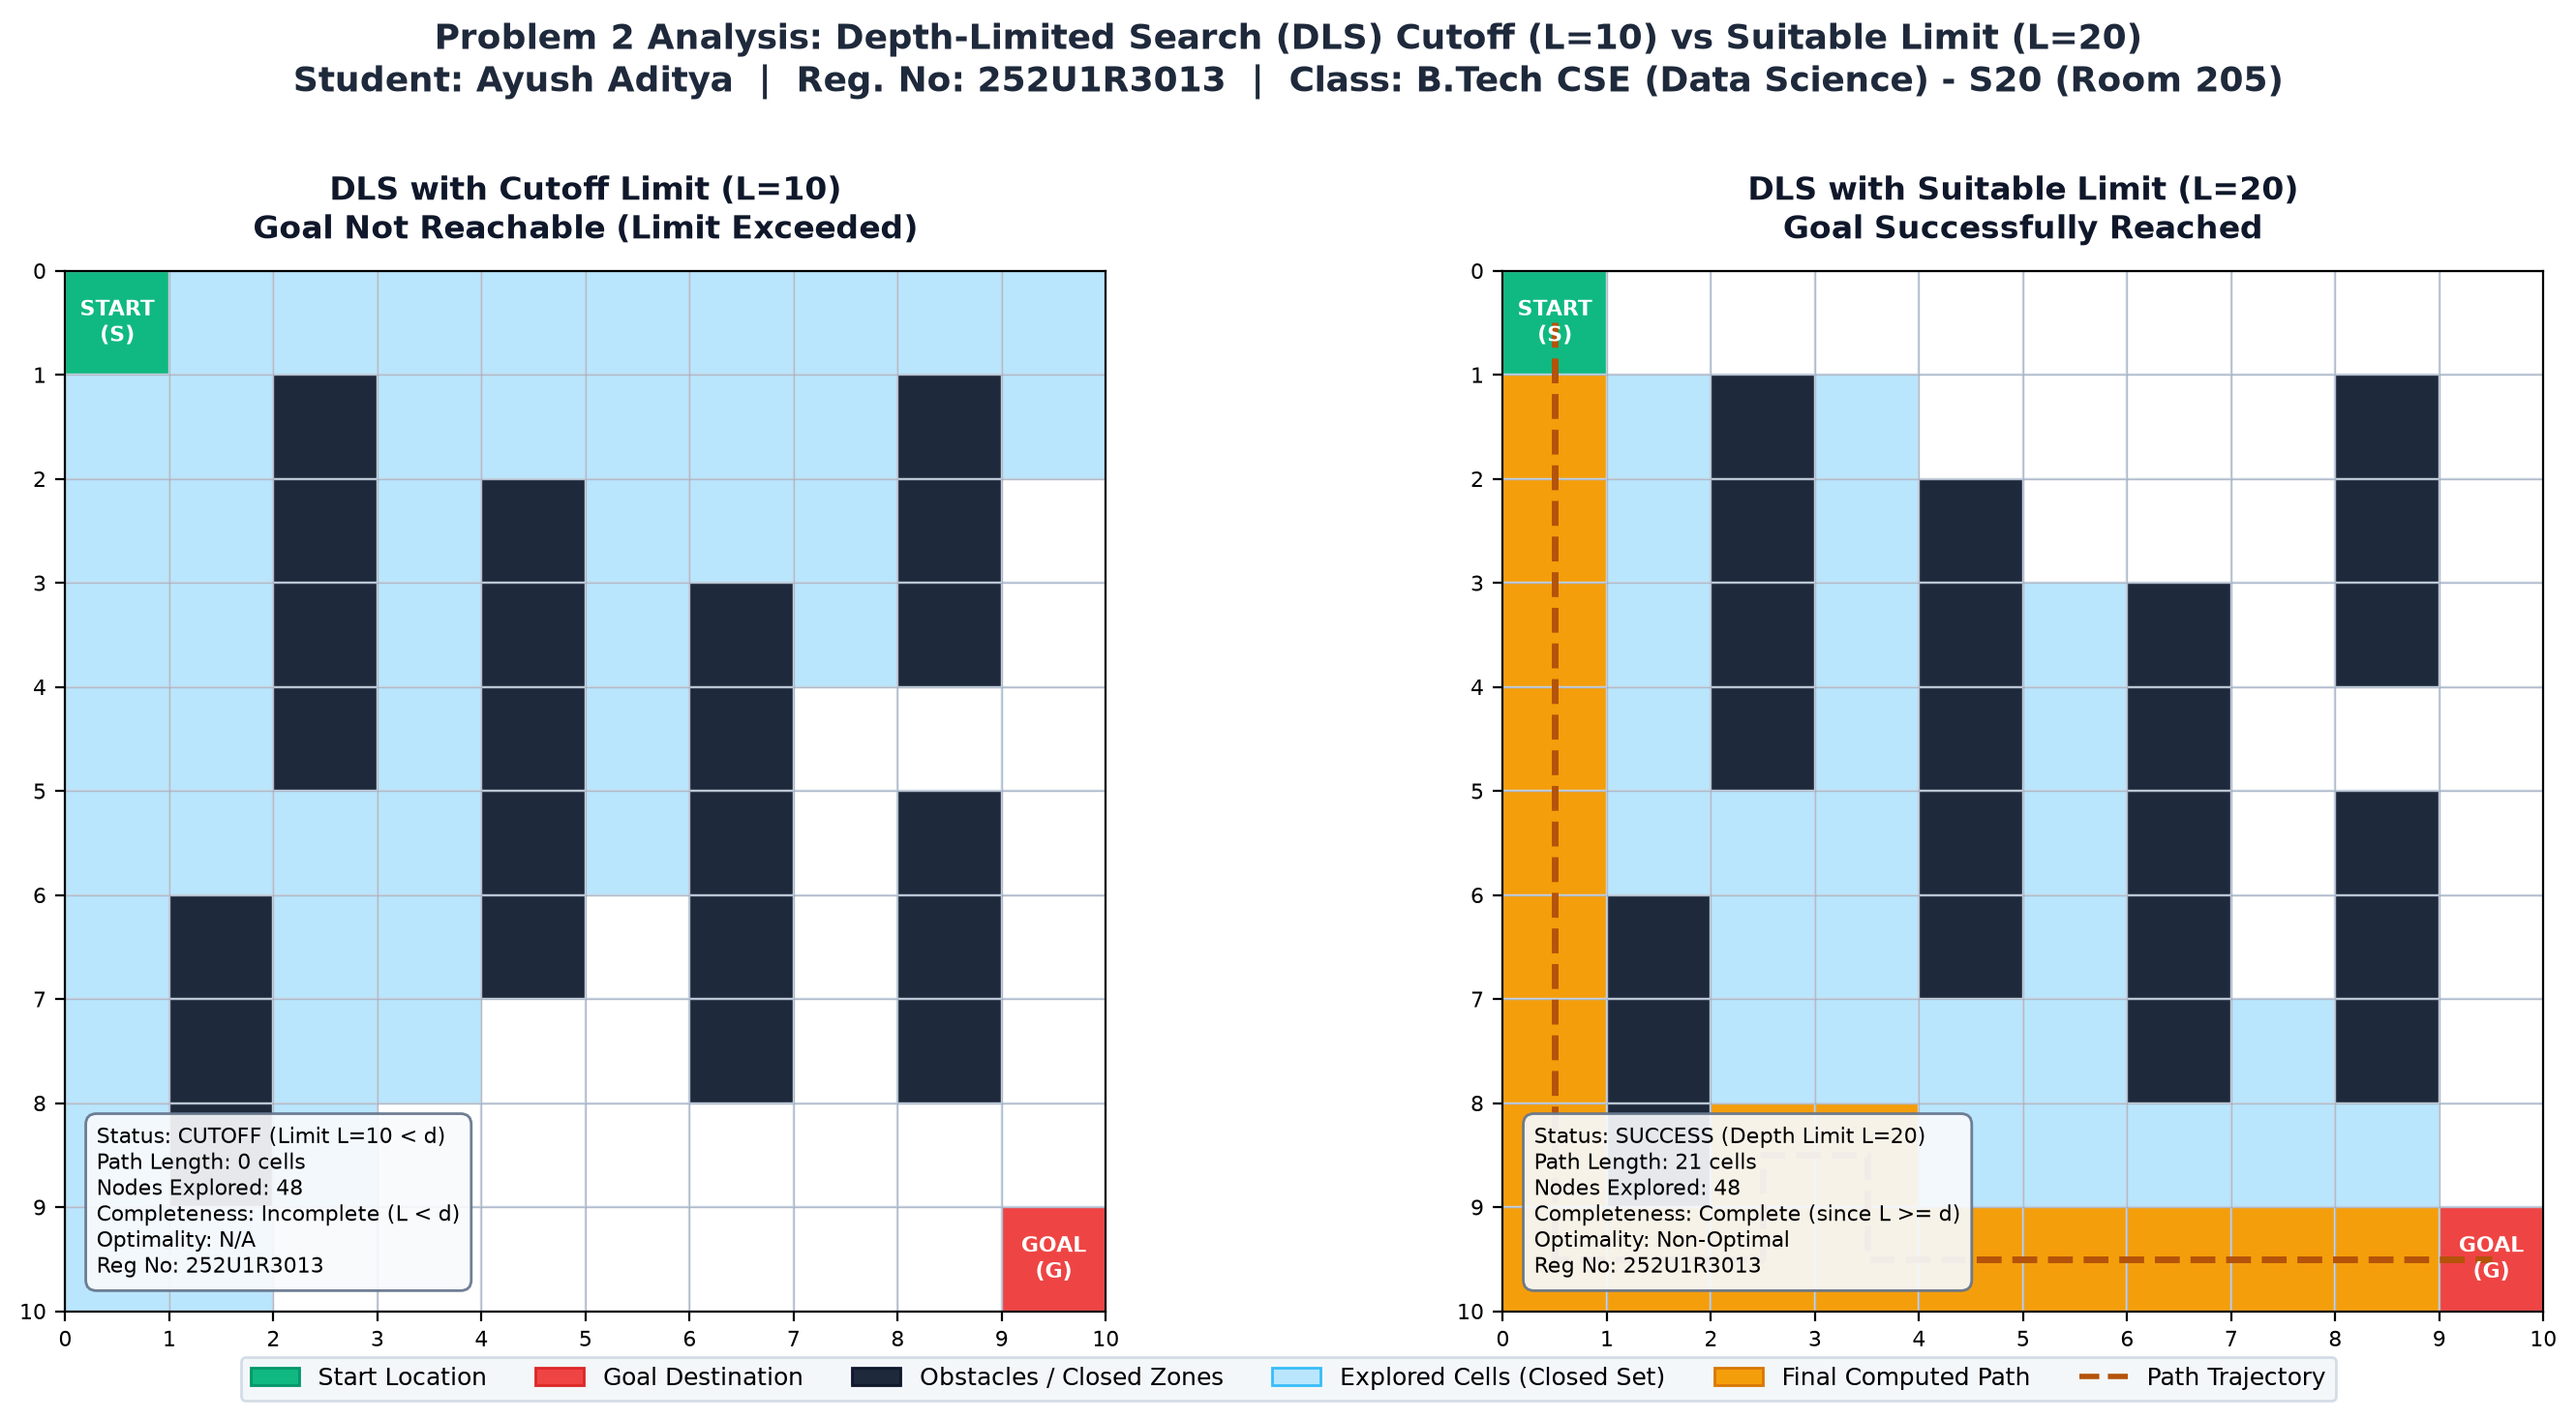

In [6]:
# ==============================================================================
# Cell 6: Problem 2 - DLS Cutoff Analysis (Limit L=10 vs Limit L=20)
# Student: Ayush Aditya | Registration Number: 252U1R3013
# ==============================================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7.5), dpi=200)

fig.suptitle(
    f"Problem 2 Analysis: Depth-Limited Search Cutoff (L=10) vs Suitable Limit (L=20)\n"
    f"Student: {STUDENT_NAME}  |  Reg. No: {REG_NO}  |  Class: {CLASS_INFO}",
    fontsize=13, fontweight="bold", color="#1E293B", y=0.98
)

render_grid_subplot(
    ax1, grid_campus, [], dls_cut_exp, entrance_start, computer_lab_goal,
    "DLS with Insufficient Limit (L=10 < d=18) -> CUTOFF",
    {"Status": "CUTOFF (Path Incomplete)", "Path Length": "None", "Nodes Explored": len(dls_cut_exp), "Optimality": "Incomplete"}
)

render_grid_subplot(
    ax2, grid_campus, dls_ok_path, dls_ok_exp, entrance_start, computer_lab_goal,
    "DLS with Suitable Limit (L=20 >= d=18) -> SUCCESS",
    {"Status": "SUCCESS", "Path Length": len(dls_ok_path), "Nodes Explored": len(dls_ok_exp), "Optimality": "Non-Optimal"}
)

fig.legend(handles=legend_elements, loc="lower center", ncol=6, fontsize=9,
           frameon=True, facecolor="#F1F5F9", edgecolor="#CBD5E1", bbox_to_anchor=(0.5, 0.02))

plt.tight_layout(rect=[0, 0.07, 1, 0.94])
plt.show()


### **3.4 Theoretical & Experimental Comparison: BFS vs DLS**

| Evaluation Metric | Breadth-First Search (BFS) | Depth-Limited Search (DLS, $L=20$) | Depth-Limited Search (DLS, $L=10$) |
| :--- | :--- | :--- | :--- |
| **Completeness** | **Complete** | **Complete** (since $L=20 \ge d=18$) | **Incomplete** (terminated with `CUTOFF` since $L < d$) |
| **Optimality** | **Optimal** (Shortest path guaranteed) | **Non-Optimal** (Finds valid path within limit) | **N/A** (No solution found) |
| **Time Complexity** | $O(b^d)$ | $O(b^L)$ | $O(b^L)$ |
| **Space Complexity** | $O(b^d)$ (Exponential memory footprint) | **$O(b \cdot L)$ (Strictly Linear memory)** | **$O(b \cdot L)$ (Strictly Linear memory)** |
| **Nodes Explored** | 77 cells | **48 cells** (Focused search cone) | 48 cells (Pruned at boundary) |
| **Path Length** | **19 cells (18 steps)** | 21 cells (20 steps) | None (Cutoff occurred) |

### **Key Architectural Insights (Module 2):**
1. **DLS Eliminates the Infinite Loop Trap of Standard DFS:** In environments with loops or infinite depth, DFS can enter infinite recursion. DLS strictly bounds maximum depth.
2. **DLS drastically saves memory compared to BFS:** While BFS stores all frontier nodes across every level ($O(b^d)$), DLS uses only linear memory $O(b \cdot L)$.
3. **The Essential Challenge of DLS is Choosing $L$:**
   - If $L < d$, the search is incomplete (as evidenced by our $L=10$ cutoff experiment).
   - If $L > d$, the search consumes more time than necessary and may return a non-optimal path.
   - This limitation sets the exact motivation for **Iterative Deepening Search (IDDFS)** covered later in Module 2, which systematically increases $L=1, 2, 3, \dots$ to combine BFS optimality with DLS linear memory.


## 4. Comprehensive Summary & Lab Conclusion

### **4.1 Unified Algorithm Comparison Matrix**

| Characteristic | Breadth-First Search (BFS) | Depth-First Search (DFS) | Depth-Limited Search (DLS) |
| :--- | :--- | :--- | :--- |
| **Search Strategy** | Level-by-level (FIFO queue) | Deepest branch first (LIFO stack) | Depth-bounded branch exploration ($L$) |
| **Completeness** | Yes (if $b < \infty$) | Yes (in finite state space with cycle check) | Yes if $L \ge d$; Incomplete if $L < d$ |
| **Optimality** | **Yes** (uniform step cost) | **No** | **No** |
| **Time Complexity** | $O(b^d)$ | $O(b^m)$ | $O(b^L)$ |
| **Space Complexity** | $O(b^d)$ (Memory intensive) | $O(b \cdot m)$ (Linear memory) | $O(b \cdot L)$ (Linear memory) |
| **Problem 1 (Hospital)** | 19 cells (Shortest, safest route) | 27 cells (Valid but winding) | — |
| **Problem 2 (Campus)** | 19 cells (Optimal walkway route) | — | 21 cells ($L=20$, memory-bounded) |

### **4.2 Conclusion**
- For the **Hospital Delivery Robot (Problem 1)**, **Breadth-First Search (BFS)** is the superior algorithm. In clinical healthcare, minimizing patient delivery latency and taking the shortest obstacle-free corridor is a paramount safety requirement.
- For the **College Campus Navigation (Problem 2)**, while BFS produces the shortest route, **Depth-Limited Search (DLS)** offers a compelling alternative when memory resources are constrained (e.g., embedded campus kiosks or microcontrollers), provided the depth budget $L$ is selected such that $L \ge d$.
- Both experiments successfully validate the foundational tenets of uninformed blind search as specified in Module 1 and Module 2 of the Fundamentals of Artificial Intelligence syllabus.
